# 03 · Validaciones y comparación de las seis familias

Qué hace. Construye y compara seis maneras de validar (CV aleatoria, bloques de 2 km, bloques con buffer de 300 m,
clústeres k-means, kNNDM y Chapinero fuera) y compara las siete especificaciones de las seis familias que exige el taller
(regresión lineal, Elastic Net, CART, Random Forest, boosting con LightGBM y CatBoost, y una red neuronal con atención a
vecinos), todas con las mismas 162 variables y los mismos pliegues. Cierra con el bootstrap pareado, la relación con
Kaggle y las pruebas que no entraron al modelo final (mezcla, kriging de residuos, BETO).

Cómo. Los pliegues se reconstruyen con `validacion_clase.py` y `espacial.py` (es barato). Los errores fuera de pliegue
de cada familia se leen de `stores/cv_clase_oof_*.parquet` y `stores/cv_clase_res_*.csv`, que produjo `cv_clase.py`
(MODO = cv, unos 22 minutos con 6 procesos). Con `RECALCULAR = True` se vuelven a ajustar todas las familias y los
resultados se escriben en `stores/recalculo/`.

Para qué. Responde las Etapas 2 y 3 del enunciado: qué familia predice mejor, por qué, si la validación estándar y la
espacial eligen el mismo ganador y cuál anticipa mejor el puntaje de Kaggle.

Conceptos de clase que usa:

| Concepto | Dónde se enseña | Sección |
|---|---|---|
| La CV aleatoria subestima el error con dependencia espacial ($2\sigma^2\rho$) | Lecture 14, diap. 25 y 44 | 1 |
| Bloques, buffer y dejar una zona por fuera; la partición interna sigue la lógica externa | Lecture 14, diap. 26 a 31; lectura Validación cruzada espacial | 1 |
| Ejercicio "imitando el taller" (zona no vista como prueba) | Lecture 14, cuaderno 01_SpatialData | 1 |
| kNNDM: pliegues con la misma distancia al vecino que la prueba | Milà y otros (2022), fuera del material del curso | 1.3 |
| Regresión lineal, Elastic Net, árboles, bosques y boosting | ISLR cap. 6 y 8 (fuera de la carpeta de lecturas) | 2 |
| Red con atención; dropout, normalización por lotes, AdamW, parada temprana | Lecture 12, diap. 20 a 28; Vaswani y otros (2017) | 2 |
| Intervalos por bootstrap | material general del curso | 4 |

Orden de ejecución: después de `02`. Tiempo: cerca de 1 minuto con `RECALCULAR = False`.

## 0. Configuración

In [1]:
# False: lee los resultados guardados. True: vuelve a ajustar las 7 especificaciones con validación cruzada (unos 25
# minutos con 6 procesos) y escribe solo en stores/recalculo/.
RECALCULAR = False

import warnings
warnings.filterwarnings("ignore")
import json
import time

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from scipy.stats import spearmanr

import cuadernos_utils as cu
from cuadernos_utils import coma, tabla_coma

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 30)
t0 = time.time()


def guardar_figura(fig, nombre):
    fig.savefig(cu.VIEWS / f"03_{nombre}.png")


F = cu.cargar_flujo("aleatoria,bloques,bloques_buffer,clusters")      # base y pliegues de los cuatro esquemas
g, y, idx_tr, idx_te = F.g, F.y, F.idx_tr, F.idx_te
xy = np.c_[F.xs, F.ys]
import espacial as es_mod                      # kNNDM y kriging (scripts/espacial.py)
loc = gpd.read_file(cu.STORES / "localidades_bogota.geojson").to_crs("EPSG:9377")
chap = loc[loc["localidad"] == "Chapinero"]

[  0.1 min] Variables: estructurales 15, externas 24 + adicionales 26, texto 83, BETO PCA 32, BETO ajustado 1


[  0.2 min] AUC adversarial (composición): 0.922


[  0.2 min] V3: 20,144 avisos en 80 bloques de 1 km


[  0.2 min] Variables: sin Catastro 150 | con Catastro 161 (+ puntaje de texto)


[  0.2 min] aleatoria: 5 pliegues | validación 38,644 | entrenamiento medio 30,915 | parada interna media 6,183


[  0.2 min] bloques: 5 pliegues | validación 38,644 | entrenamiento medio 30,915 | parada interna media 5,755


[  0.2 min] bloques_buffer: 5 pliegues | validación 38,644 | entrenamiento medio 27,190 | parada interna media 4,197


[  0.2 min] clusters: 10 pliegues | validación 38,644 | entrenamiento medio 34,780 | parada interna media 4,472


[  0.2 min] Chapinero (imitando el taller): 1 pliegues | validación 307 | entrenamiento medio 38,337 | parada interna media 2,074


[  0.2 min] Fin


## 1. Seis maneras de validar

Con dependencia espacial, el ruido de dos avisos cercanos está correlacionado. Si $u_i$ y $u_j$ tienen varianza
$\sigma^2$ y correlación $\rho$, y un modelo flexible aprende el ruido de $j$, la CV aleatoria (que valida $i$ con su
vecino $j$ en el entrenamiento) subestima el error esperado en una zona nueva en aproximadamente $2\sigma^2\rho$
(Lecture 14, diap. 25). Los esquemas espaciales cambian solo cómo se arman los pliegues:

| Esquema | Cómo se arma | Pliegues | Partición interna (parada temprana) |
|---|---|---|---|
| CV aleatoria | `vfold_cv`: avisos al azar | 5 | 80 % y 20 % al azar |
| Bloques de 2 km | celdas de 2.000 m asignadas al azar a los pliegues (`spatial_block_cv`) | 5 | primer pliegue de bloques sobre el entrenamiento |
| Bloques con buffer | lo mismo, y se sacan del entrenamiento los avisos a 300 m o menos de la validación | 5 | lo mismo con buffer |
| Clústeres k-means | k-means sobre las coordenadas, cada clúster es un pliegue (`spatial_clustering_cv`) | 10 | k-means sobre el entrenamiento |
| kNNDM | grupos k-means de tamaño elegido para que la distancia al vecino de entrenamiento se parezca a la de la prueba | 5 | 20 % de los grupos |
| Chapinero fuera | se entrena sin los 307 avisos de Chapinero y se predicen ("imitando el taller") | 1 | una localidad al azar |

En todos los esquemas el puntaje de texto se recalcula con el entrenamiento de cada pliegue, y las métricas se calculan
sobre las predicciones reunidas, como en la lectura Validación cruzada espacial.

### 1.1 Un pliegue de validación de cada esquema, en la coordenada exacta

kNNDM elige q = 1600 (W = 22,5); coincide con stores/knndm_resumen.csv


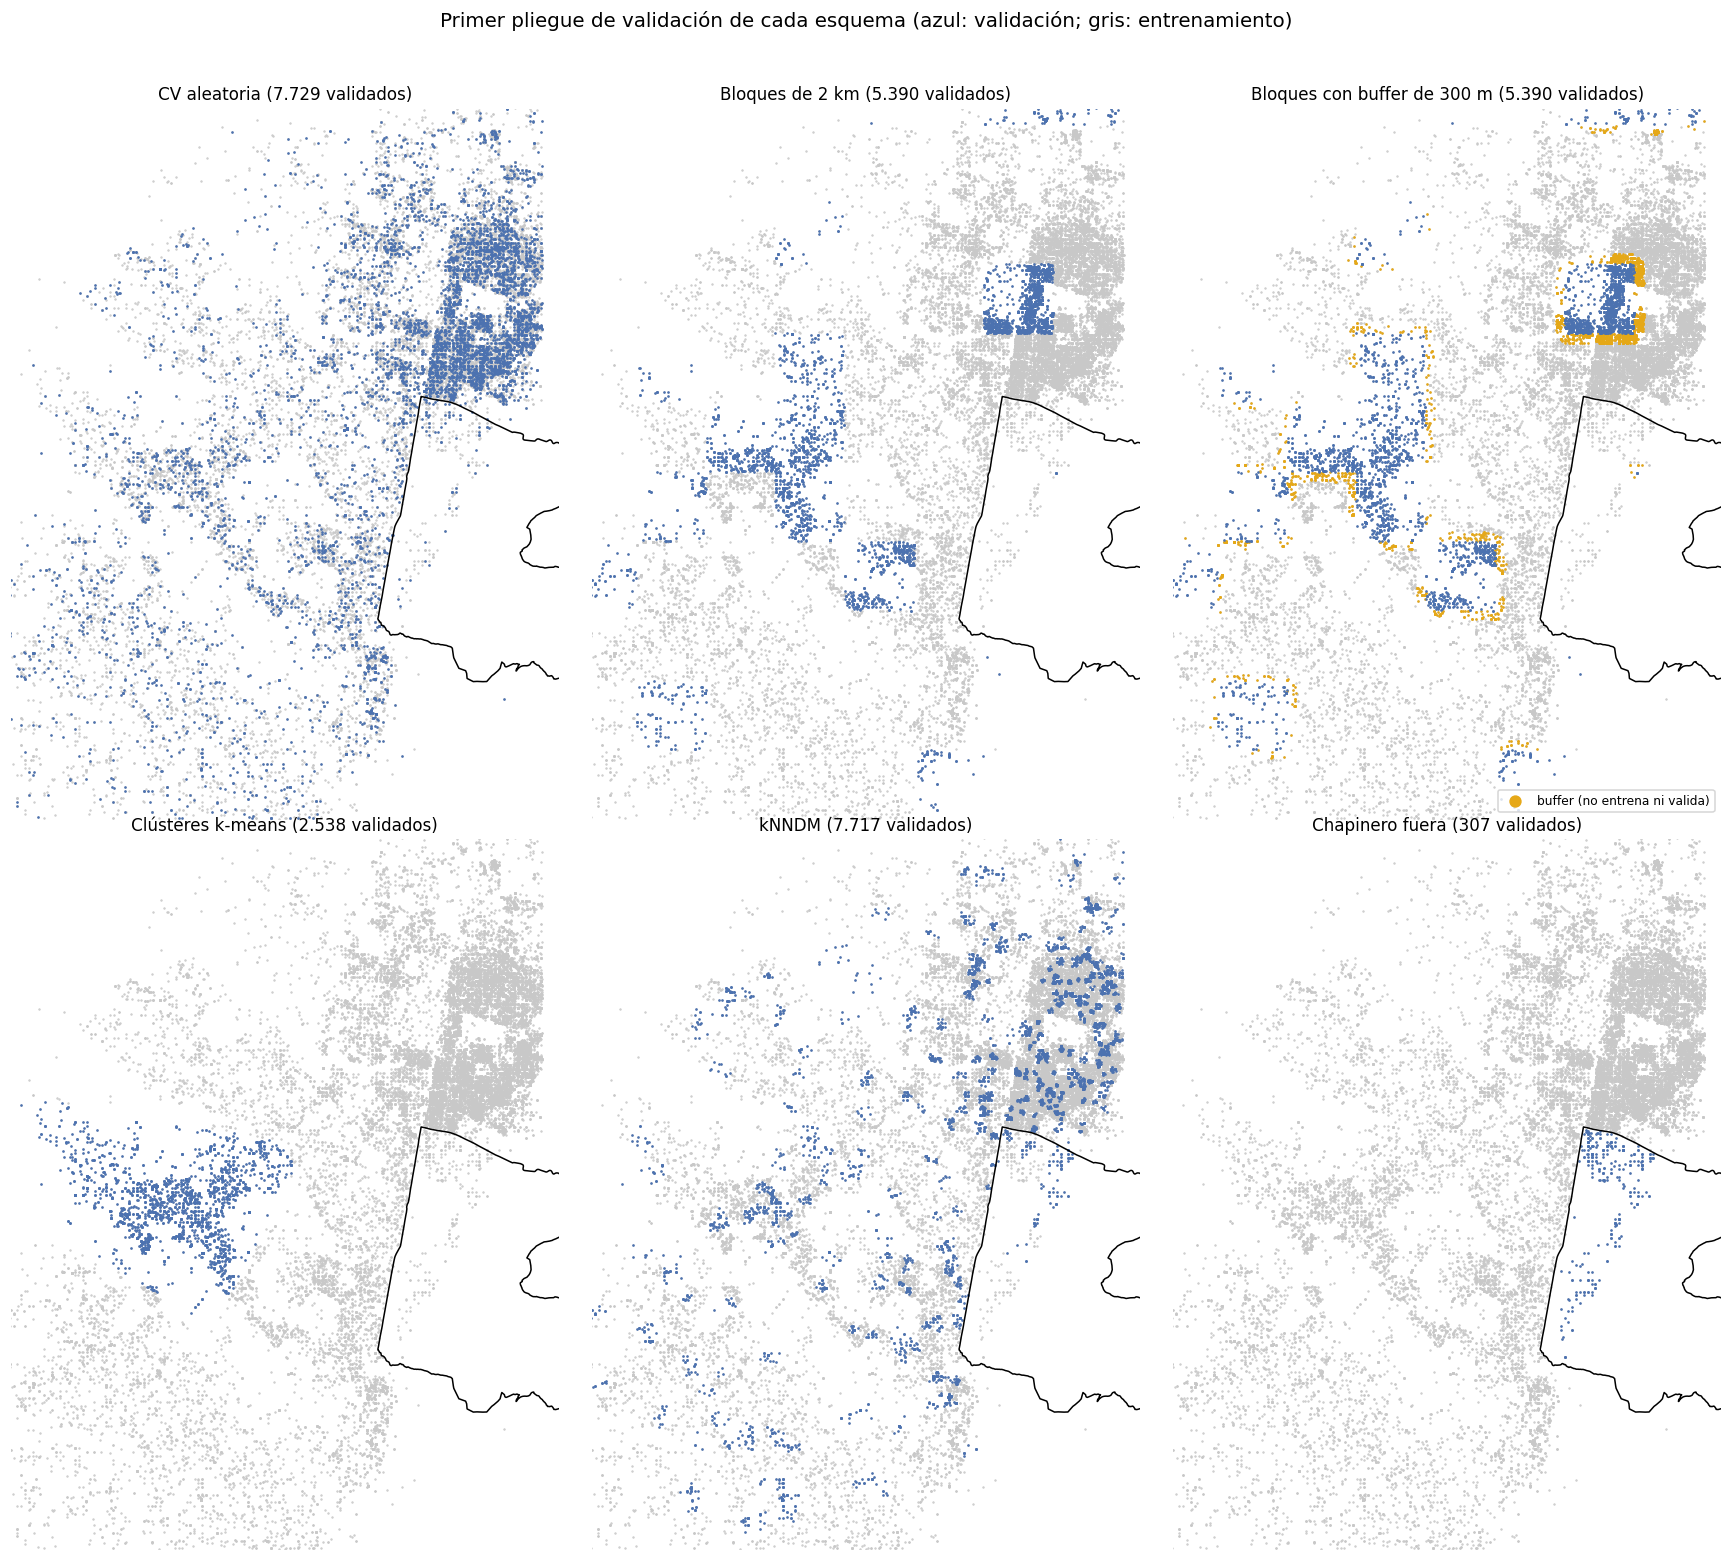

In [2]:
# kNNDM: rejilla de q (número de grupos k-means) y distancia de Wasserstein a la distribución de la prueba
fold_k, grupo_q, q_k, resumen_k, obj_k = es_mod.knndm(xy[idx_tr], xy[idx_te], k=5)
guardado = pd.read_csv(cu.STORES / "knndm_resumen.csv")
assert np.allclose(pd.DataFrame(resumen_k)["W"].values, guardado["W"].values)     # mismo resultado que rk_knndm.py
print(f"kNNDM elige q = {q_k} (W = {coma(min(r['W'] for r in resumen_k), 1)}); coincide con stores/knndm_resumen.csv")

pl = F.PLIEGUES_CLASE
validacion = {
    "CV aleatoria": pl["aleatoria-0"][2], "Bloques de 2 km": pl["bloques-0"][2],
    "Bloques con buffer de 300 m": pl["bloques_buffer-0"][2], "Clústeres k-means": pl["clusters-0"][2],
    "kNNDM": idx_tr[fold_k == 0], "Chapinero fuera": F.PLIEGUES["Chapinero"][1],
}
quitados_buffer = np.setdiff1d(idx_tr, np.r_[pl["bloques_buffer-0"][1], pl["bloques_buffer-0"][2]])
fig, axes = plt.subplots(2, 3, figsize=(16, 14))
b_ = np.r_[np.percentile(F.xs[idx_tr], 0.5) - 500, np.percentile(F.ys[idx_tr], 0.5) - 500,
           np.percentile(F.xs[idx_tr], 99.5) + 500, np.percentile(F.ys[idx_tr], 99.5) + 500]
for ax, (nombre, iv) in zip(axes.ravel(), validacion.items()):
    ax.scatter(F.xs[idx_tr], F.ys[idx_tr], s=0.3, color="#C8C8C8")
    if nombre.startswith("Bloques con"):
        ax.scatter(F.xs[quitados_buffer], F.ys[quitados_buffer], s=0.5, color="#E6A817", label="buffer (no entrena ni valida)")
        ax.legend(markerscale=10, loc="lower right", fontsize=8)
    ax.scatter(F.xs[iv], F.ys[iv], s=0.5, color="#4C72B0")
    chap.boundary.plot(ax=ax, color="black", lw=1)
    ax.set_xlim(b_[0], b_[2]); ax.set_ylim(b_[1], b_[3]); ax.set_axis_off()
    ax.set_title(f"{nombre} ({len(iv):,} validados)".replace(",", "."), fontsize=11)
fig.suptitle("Primer pliegue de validación de cada esquema (azul: validación; gris: entrenamiento)", fontsize=13, y=1.01)
fig.tight_layout()
guardar_figura(fig, "pliegues_mapa")
plt.show()

### 1.2 Distancia al vecino de entrenamiento más cercano

Lo que decide qué tan difícil es una validación es cuán lejos queda cada aviso validado de lo que el modelo vio. Se compara
con la tarea real: cada aviso de prueba frente al entrenamiento completo.

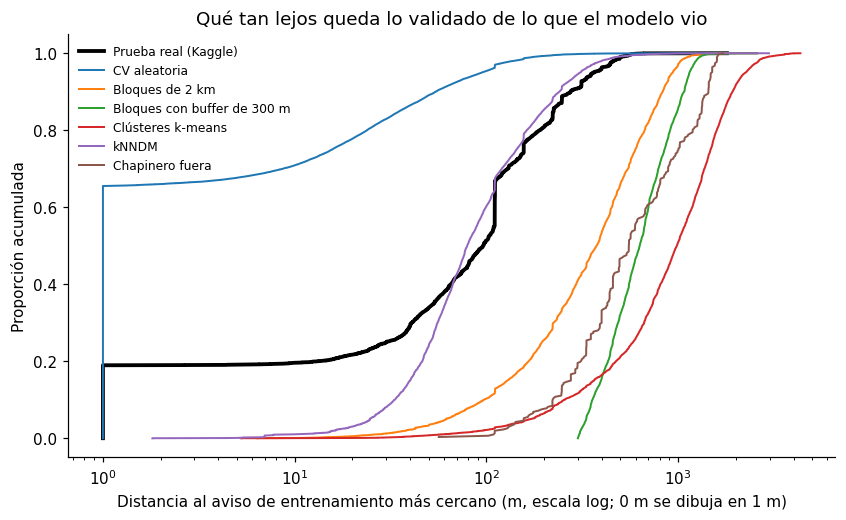

,% a 0 m (misma coordenada),mediana (m),percentil 90 (m)
Prueba real (Kaggle),19,96,275
CV aleatoria,66,0,54
Bloques de 2 km,0,375,830
Bloques con buffer de 300 m,0,631,1.074
Clústeres k-means,0,985,1.921
kNNDM,0,79,240
Chapinero fuera,0,553,1.437


In [3]:
def dist_esquema(prefijo):
    d = [cKDTree(xy[a]).query(xy[b])[0] for n, (e, a, b, _) in pl.items() if e == prefijo]
    return np.concatenate(d)


dist = {"Prueba real (Kaggle)": cKDTree(xy[idx_tr]).query(xy[idx_te])[0],
        "CV aleatoria": dist_esquema("aleatoria"), "Bloques de 2 km": dist_esquema("bloques"),
        "Bloques con buffer de 300 m": dist_esquema("bloques_buffer"), "Clústeres k-means": dist_esquema("clusters"),
        "kNNDM": es_mod.distancias_cv(xy[idx_tr], fold_k),
        "Chapinero fuera": cKDTree(xy[F.PLIEGUES["Chapinero"][0]]).query(xy[F.PLIEGUES["Chapinero"][1]])[0]}
tab_d = pd.DataFrame({k: {"% a 0 m (misma coordenada)": 100 * np.mean(v < 1), "mediana (m)": np.median(v),
                          "percentil 90 (m)": np.percentile(v, 90)} for k, v in dist.items()}).T
fig, ax = plt.subplots(figsize=(9, 5))
for k, v in dist.items():
    s = np.sort(np.maximum(v, 1))
    ax.plot(s, np.arange(1, len(s) + 1) / len(s), lw=2.5 if k.startswith("Prueba") else 1.3,
            color="black" if k.startswith("Prueba") else None, label=k)
ax.set_xscale("log")
ax.set(xlabel="Distancia al aviso de entrenamiento más cercano (m, escala log; 0 m se dibuja en 1 m)",
       ylabel="Proporción acumulada", title="Qué tan lejos queda lo validado de lo que el modelo vio")
ax.legend(frameon=False, fontsize=8)
guardar_figura(fig, "distancia_vecino")
plt.show()
tabla_coma(tab_d, 0)

La CV aleatoria valida dos de cada tres avisos con otro aviso en la misma coordenada dentro del entrenamiento; en la prueba
real eso pasa solo con el 19 %. kNNDM es el esquema que más se parece a la prueba en esta distancia, pero mezcla toda
Bogotá, que es más barata y más parecida al entrenamiento. Chapinero fuera es más exigente que la prueba en distancia
(el modelo final sí vio los 307 avisos de Chapinero) pero es el único que pide predecir el mercado de Chapinero.

### 1.3 kNNDM (Milà y otros, 2022)

Para cada $q$ de una rejilla se agrupan las coordenadas de entrenamiento con k-means en $q$ grupos, los grupos se reparten
en 5 pliegues de tamaño parecido y se mide la distancia de Wasserstein entre la distribución de distancias de la validación
$G^*$ y la de la prueba $G$:

$$W_1(G^*, G) = \int_0^\infty \big| F_{G^*}(d) - F_G(d) \big|\, \mathrm{d}d, \qquad q^* = \arg\min_q W_1$$

In [4]:
rk_tab = pd.DataFrame(resumen_k).set_index("q")
rk_tab.columns = ["W (m)", "mediana (m)", "percentil 90 (m)", "% a 0 m"]
tabla_coma(rk_tab, 1)

,W (m),mediana (m),percentil 90 (m),% a 0 m
q,,,,
10,"1.152,9","1.180,6","2.152,7","0,0"
25,"507,3","474,5","1.334,8","0,0"
50,"381,7","427,9","974,3","0,0"
100,"222,1","283,5","663,4","0,0"
200,"124,5","192,9","474,1","0,0"
400,"72,7","149,1","379,2","0,0"
800,"26,1","106,4","285,1","0,0"
1600,"22,5","79,4","240,3","0,0"
3200,"35,4","61,5","199,9","1,0"


## 2. Las siete especificaciones

Todas reciben las mismas 161 variables con Catastro más el puntaje de texto del pliegue, y la misma partición interna
para elegir su hiperparámetro de complejidad. Ninguna recorta la predicción al rango del entrenamiento.

| Familia | Especificación (`modelo_utils.ajustar_predecir`) | Qué se elige con la partición interna |
|---|---|---|
| Regresión lineal | MCO sobre variables estandarizadas, faltantes imputados con la mediana más indicadores | nada |
| Elastic Net | $\min_\beta \frac{1}{2n}\lVert y - X\beta\rVert^2 + \lambda[\alpha\lVert\beta\rVert_1 + \frac{1-\alpha}{2}\lVert\beta\rVert_2^2]$ | $\lambda$ (30 valores) y $\alpha \in \{0{,}1; 0{,}5; 0{,}9; 1\}$ con 3 particiones espaciales |
| CART | árbol de regresión, al menos 20 avisos por hoja | profundidad en {6, 8, 10, 12, 15} |
| Random Forest | 300 árboles, 30 % de variables por corte, 5 avisos por hoja | nada (valores fijos) |
| LightGBM | boosting L2, 63 hojas, η = 0,05 (cuaderno 02) | número de árboles |
| CatBoost | boosting RMSE, árboles simétricos de profundidad 8, η = 0,05, λ = 3 | número de árboles |
| Red con atención | ver abajo; pérdida L1, AdamW, dropout 0,2, normalización por lotes | número de épocas (paciencia 12) |

Red con atención a vecinos (inspirada en Viana y Barbosa, 2021). Para el aviso $i$ se toman sus $k = 20$ vecinos de
entrenamiento $j$ (sin la misma coordenada ni duplicados de texto), descritos por $\mathbf{h}_j$ (log-precio, log-precio
por m², área, alcobas, baños, tipo) y la distancia $d_{ij}$:

$$\mathbf{e}_i = \text{MLP}(\mathbf{x}_i), \qquad \alpha_{ij} = \operatorname{softmax}_j\!\left(\frac{\mathbf{q}(\mathbf{e}_i)^{\top}\mathbf{k}(\mathbf{h}_j, d_{ij})}{\sqrt{d_a}}\right), \qquad
\hat y_i = g\Big(\mathbf{e}_i, \sum_j \alpha_{ij}\, \mathbf{v}(\mathbf{h}_j, d_{ij})\Big)$$

Es la atención de producto escalar de Vaswani y otros (2017) aplicada a los vecinos en el espacio.

## 3. Resultados: error fuera de pliegue por familia y esquema

In [5]:
FAMILIAS = ["lightgbm", "catboost", "random_forest", "cart", "nn_atencion", "elastic_net", "ols"]
ESQ = {"aleatoria": "CV aleatoria", "bloques": "Bloques de 2 km", "bloques_buffer": "Bloques con buffer",
       "clusters": "Clústeres k-means", "Chapinero (imitando el taller)": "Chapinero fuera"}

if RECALCULAR:
    # Mismo cálculo que MODO=cv de cv_clase.py, para las 7 especificaciones y los 5 esquemas (unos 25 minutos)
    for f in FAMILIAS:
        o = F.oof_clase(f, "con")
        o.to_parquet(cu.ruta_salida(f"cv_clase_oof_{f}_con.parquet", RECALCULAR), index=False)
        pd.DataFrame(F.metricas(o)).assign(modelo=F.NOMBRE[f], catastro="con").to_csv(
            cu.ruta_salida(f"cv_clase_res_{f}_con.csv", RECALCULAR), index=False)
    origen = cu.RECALCULO
else:
    origen = cu.STORES
res = pd.concat([pd.read_csv(origen / f"cv_clase_res_{f}_con.csv") for f in FAMILIAS])
res["esquema"] = res["esquema"].map(ESQ)
mae = res.pivot(index="modelo", columns="esquema", values="MAE")[list(ESQ.values())]
sesgo = res.pivot(index="modelo", columns="esquema", values="Sesgo")[list(ESQ.values())]
mae = mae.sort_values("Chapinero fuera")
rk = pd.read_csv(cu.STORES / "rk_knndm_res_lightgbm_con.csv").set_index("variante")
mae.loc["LightGBM", "kNNDM"] = rk.loc["sin kriging", "MAE kNNDM"]
print("MAE en millones (las celdas vacías no se calcularon: CatBoost y la red solo con clústeres y Chapinero fuera,")
print("más la CV aleatoria en la red; bloques y kNNDM solo para LightGBM, por tiempo)")
tabla_coma(mae).replace("NA", "")

MAE en millones (las celdas vacías no se calcularon: CatBoost y la red solo con clústeres y Chapinero fuera,
más la CV aleatoria en la red; bloques y kNNDM solo para LightGBM, por tiempo)


esquema,CV aleatoria,Bloques de 2 km,Bloques con buffer,Clústeres k-means,Chapinero fuera,kNNDM
modelo,,,,,,
LightGBM,"78,8","119,1","123,1","125,0","143,8","111,7"
CatBoost,,,,"124,1","150,1",
Random Forest,"91,6",,,"131,8","158,6",
CART,"117,9",,,"150,9","174,1",
Red con atención,"86,8",,,"128,8","176,7",
Elastic Net,"124,5",,,"149,8","185,2",
Regresión lineal,"124,7",,,"150,0","185,7",


In [6]:
print("Sesgo (media de la predicción menos el precio real, millones)")
tabla_coma(sesgo.loc[mae.index]).replace("NA", "")

Sesgo (media de la predicción menos el precio real, millones)


esquema,CV aleatoria,Bloques de 2 km,Bloques con buffer,Clústeres k-means,Chapinero fuera
modelo,,,,,
LightGBM,"2,3","1,5","3,3","5,4","-52,3"
CatBoost,,,,"3,8","-66,2"
Random Forest,"1,9",,,"7,1","-82,1"
CART,"1,8",,,"-7,9","-104,7"
Red con atención,"-18,3",,,"-21,5","-115,5"
Elastic Net,"0,2",,,"4,8","-33,9"
Regresión lineal,"0,2",,,"4,7","-33,6"


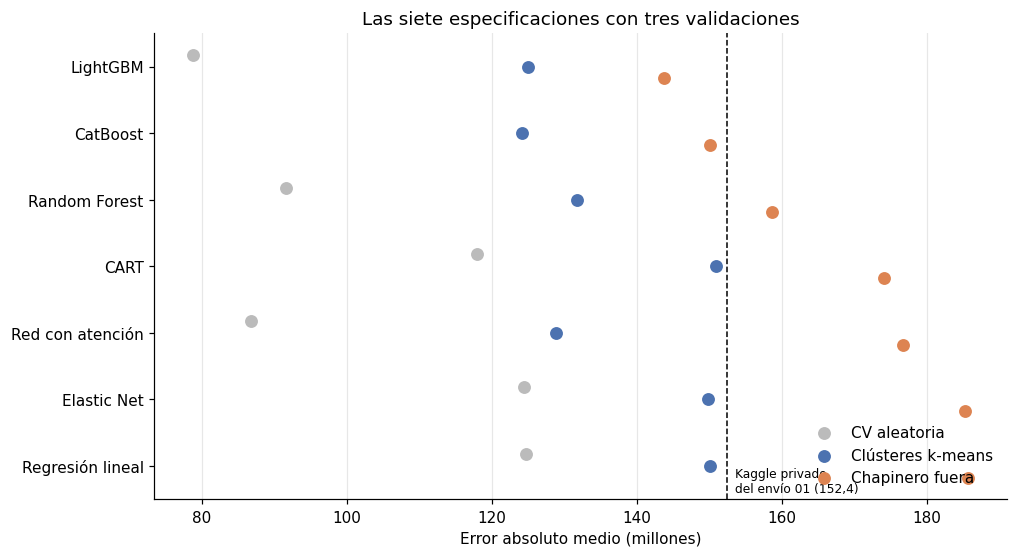

In [7]:
fig, ax = plt.subplots(figsize=(10, 5.5))
colores = {"CV aleatoria": "#BBBBBB", "Clústeres k-means": "#4C72B0", "Chapinero fuera": "#DD8452"}
pos = np.arange(len(mae))
for k, (esq, col) in enumerate(colores.items()):
    ax.scatter(mae[esq], pos + (k - 1) * 0.18, color=col, s=55, label=esq, zorder=3)
ax.set_yticks(pos, mae.index)
ax.invert_yaxis()
ax.axvline(152.43, color="black", ls="--", lw=1)
ax.text(153.5, len(mae) - 0.6, "Kaggle privado\ndel envío 01 (152,4)", fontsize=8)
ax.set(xlabel="Error absoluto medio (millones)", title="Las siete especificaciones con tres validaciones")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="x", alpha=0.3)
guardar_figura(fig, "familias_validaciones")
plt.show()

In [8]:
# ¿La validación estándar y la espacial eligen el mismo ganador y el mismo orden?
comunes = mae[["CV aleatoria", "Clústeres k-means", "Chapinero fuera"]].dropna()
orden = comunes.rank().astype(int)
rho_ac = spearmanr(comunes["CV aleatoria"], comunes["Chapinero fuera"])[0]
print("Ganador por esquema:", {c: mae[c].idxmin() for c in ["CV aleatoria", "Clústeres k-means", "Chapinero fuera"]})
print(f"Correlación de rangos entre CV aleatoria y Chapinero fuera (6 especificaciones con ambas): {coma(rho_ac, 2)}")
orden

Ganador por esquema: {'CV aleatoria': 'LightGBM', 'Clústeres k-means': 'CatBoost', 'Chapinero fuera': 'LightGBM'}
Correlación de rangos entre CV aleatoria y Chapinero fuera (6 especificaciones con ambas): 0,83


esquema,CV aleatoria,Clústeres k-means,Chapinero fuera
modelo,,,
LightGBM,1,1,1
Random Forest,3,3,2
CART,4,6,3
Red con atención,2,2,4
Elastic Net,5,4,5
Regresión lineal,6,5,6


Lectura.

1. El boosting gana con las tres validaciones; LightGBM es el mejor de las seis familias con la CV aleatoria y con
   Chapinero fuera, y CatBoost lo supera por 0,9 millones en clústeres. Cambia el nivel del error, no el ganador.
2. La red con atención es segunda en CV aleatoria (86,8) y cae detrás de Random Forest y CART en Chapinero fuera (176,7):
   depende de los precios de vecinos, y en una zona nueva sus vecinos son de otro mercado.
3. Los modelos lineales tienen el menor sesgo en Chapinero (−34): extrapolan con una recta. Los árboles asignan a valores
   fuera de rango la última hoja y subestiman más (−52 a −116). Pero el error de los lineales es el mayor.
4. Todas las familias subestiman Chapinero. El problema es de los datos (el entrenamiento casi no tiene Chapinero), no de
   una familia en particular.

## 4. ¿Son reales las diferencias? Bootstrap pareado en Chapinero fuera

Con 307 avisos el MAE es ruidoso. Se remuestrean los avisos con reemplazo ($B = 10.000$) y en cada réplica se calcula la
diferencia de MAE frente a LightGBM sobre los mismos avisos:

$$\Delta^{(b)}_m = \frac{1}{n}\sum_{i \in S^{(b)}} \big(|e_{im}| - |e_{i,\text{LGBM}}|\big), \qquad
\text{IC}_{95} = \big[\Delta_{(0{,}025)},\ \Delta_{(0{,}975)}\big]$$

Al usar los mismos avisos en cada réplica se elimina la variación común y el intervalo de la diferencia es mucho más
estrecho que el de cada MAE.

In [9]:
oofs = {f: pd.read_parquet(origen / f"cv_clase_oof_{f}_con.parquet") for f in FAMILIAS}
base = oofs["lightgbm"][oofs["lightgbm"]["esquema"].str.startswith("Chapinero")].set_index("idx")
real = base["real"].to_numpy()
pred = {f: oofs[f][oofs[f]["esquema"].str.startswith("Chapinero")].set_index("idx").loc[base.index, "pred"].to_numpy()
        for f in FAMILIAS}
err = {"LightGBM": np.abs(pred["lightgbm"] - real),
       "LightGBM ×1,08": np.abs(cu.CENTRO + cu.FACTOR * (pred["lightgbm"] - cu.CENTRO) - real)}
for f in FAMILIAS[1:]:
    err[F.NOMBRE[f]] = np.abs(pred[f] - real)
err["Mezcla 0,4 LightGBM + 0,6 CatBoost"] = np.abs(0.4 * pred["lightgbm"] + 0.6 * pred["catboost"] - real)
rng = np.random.default_rng(2026)
B, n = 10_000, len(real)
ib = rng.integers(0, n, (B, n))
filas = []
for k, e in err.items():
    mb = e[ib].mean(1)
    fila = {"especificación": k, "MAE": e.mean(), "IC95 bajo": np.percentile(mb, 2.5), "IC95 alto": np.percentile(mb, 97.5)}
    if k != "LightGBM":
        d = (e - err["LightGBM"])[ib].mean(1)
        fila.update({"diferencia con LightGBM": (e - err["LightGBM"]).mean(), "dif. IC95 bajo": np.percentile(d, 2.5),
                     "dif. IC95 alto": np.percentile(d, 97.5)})
    filas.append(fila)
boot = pd.DataFrame(filas).set_index("especificación")
# Coincide con el cálculo de las presentaciones (document/presentaciones/datos/ppt_bootstrap2.json)?
ref = json.load(open(cu.DATOS_PPT / "ppt_bootstrap2.json", encoding="utf-8"))
print("Diferencia máxima con ppt_bootstrap2.json en el MAE:",
      coma(max(abs(ref[c]["mae"] - boot.loc[k, "MAE"]) for c, k in [("lightgbm", "LightGBM"), ("catboost", "CatBoost"), ("ols", "Regresión lineal")]), 6))
tabla_coma(boot).replace("NA", "")

Diferencia máxima con ppt_bootstrap2.json en el MAE: 0,000000


,MAE,IC95 bajo,IC95 alto,diferencia con LightGBM,dif. IC95 bajo,dif. IC95 alto
especificación,,,,,,
LightGBM,"143,8","129,0","159,2",,,
"LightGBM ×1,08","140,8","126,2","155,9","-2,9","-5,8","-0,1"
CatBoost,"150,1","135,1","165,9","6,3","1,2","11,6"
Random Forest,"158,6","142,9","175,1","14,8","8,9","20,9"
CART,"174,1","155,2","194,2","30,3","20,3","40,4"
Red con atención,"176,7","158,4","195,6","32,9","21,4","44,8"
Elastic Net,"185,2","168,7","202,7","41,5","30,8","52,1"
Regresión lineal,"185,7","168,6","203,6","41,9","30,6","53,0"
"Mezcla 0,4 LightGBM + 0,6 CatBoost","146,8","132,0","162,2","3,0","-0,1","6,2"


Ningún intervalo de diferencia de las demás familias contiene el cero: LightGBM es mejor que cada una con 95 % de
confianza en Chapinero fuera (CatBoost por poco: 1,2 a 11,6). El ×1,08 mejora 2,9 millones con un intervalo que roza el
cero, y la mezcla con CatBoost no mejora a LightGBM solo.

## 5. Qué validación anticipa a Kaggle

Tres envíos con la misma base permiten comparar las validaciones con la tabla privada (80 % de la prueba). Para los
demás envíos del equipo (otras variables, otras personas) solo hay puntaje de Kaggle.

In [10]:
reg = pd.read_csv(cu.SUBMISSIONS / "kaggle_subidos" / "registro_envios.csv").iloc[:3]
priv = reg["puntaje_privado_80"].astype(str).str.split().str[0].astype(float).to_numpy()
cal = pd.DataFrame({"envío": ["01 LightGBM", "02 LightGBM ×1,08", "03 Mezcla 0,4 LightGBM + 0,6 CatBoost"],
                    "clústeres": reg["MAE_clusters"].astype(float).to_numpy(),
                    "Chapinero fuera": reg["MAE_chapinero_fuera"].astype(float).to_numpy(),
                    "Kaggle pública": reg["puntaje_kaggle"].astype(float).to_numpy(), "Kaggle privada": priv}).set_index("envío")
print("Orden por clústeres:", list(cal["clústeres"].rank().astype(int)), "| por Chapinero fuera:",
      list(cal["Chapinero fuera"].rank().astype(int)), "| por Kaggle privada:", list(cal["Kaggle privada"].rank().astype(int)))
print(f"La CV aleatoria (78,8) promete un error {coma(100 * (1 - 78.83 / priv[0]), 0)} % menor que el de Kaggle privado del envío 01")
tabla_coma(cal, 2)

Orden por clústeres: [3, 2, 1] | por Chapinero fuera: [2, 1, 3] | por Kaggle privada: [2, 1, 3]
La CV aleatoria (78,8) promete un error 48 % menor que el de Kaggle privado del envío 01


,clústeres,Chapinero fuera,Kaggle pública,Kaggle privada
envío,,,,
01 LightGBM,"125,00","143,80","153,50","152,43"
"02 LightGBM ×1,08","124,10","140,80","152,48","150,79"
"03 Mezcla 0,4 LightGBM + 0,6 CatBoost","123,60","146,80","155,21","153,94"


In [11]:
# Mejor envío de cada familia en Kaggle (todos los del equipo; cada familia con sus propias variables)
env = pd.read_csv(cu.DATOS_PPT / "envios_equipo.csv")
mejor = env.loc[env.groupby("familia")["privado"].idxmin()].sort_values("privado")
print(f"Envíos del equipo: {len(env)} | familias: {env['familia'].nunique()}")
tabla_coma(mejor.set_index("familia")[["archivo", "autor", "publico", "privado"]], 2)

Envíos del equipo: 27 | familias: 6


,archivo,autor,publico,privado
familia,,,,
Boosting,envio_02_lightgbm_con_catastro_x108,Sebastián Vela,"152,48","150,79"
Red neuronal,nn_clase_2x10_D_coordenadas,Sebastián Vela,"180,36","184,43"
Ensamble,superlearner_vec_boost_nn_rf,Harold Aguilera,"197,00","194,10"
Random Forest,RF_fe_depth_12_leaf_5,César Vallejo,"204,30","206,30"
CART,CART_fe_depth_6_leaf_40,César Vallejo,"240,70","239,90"
Regresión lineal,LR_fe_nr_1,César Vallejo,"244,90","253,60"


Lectura.

1. Chapinero fuera ordena los tres envíos igual que la tabla privada (02, 01, 03) y queda a 8,7 millones o menos del
   puntaje. Clústeres prefiere la mezcla (03), que en Kaggle fue la peor de las tres.
2. Entre familias, el orden de Kaggle se parece más al de la CV aleatoria que al de Chapinero fuera, pero no es una
   comparación limpia: cada envío de familia usó otras variables, y la red de Kaggle es la 2×10 de la clase, no la red con
   atención (el Elastic Net no se envió).
3. Lo que más bajó el error en Kaggle no fue cambiar de algoritmo dentro del boosting sino los datos: los LightGBM previos
   del equipo, sin Catastro ni el puntaje de texto, quedaron en 177 a 182.

## 6. Pruebas que no entraron al modelo final

In [12]:
filas = []
for conj, nom in (("sin", "sin Catastro"), ("con", "con Catastro")):
    for f in ("lightgbm", "catboost"):
        r = pd.read_csv(cu.STORES / f"cv_clase_res_{f}_{conj}.csv").set_index("esquema")
        filas.append({"prueba": f"{F.NOMBRE[f]} {nom}", "clústeres": r.loc["clusters", "MAE"],
                      "Chapinero fuera": r.loc["Chapinero (imitando el taller)", "MAE"],
                      "sesgo Chapinero": r.loc["Chapinero (imitando el taller)", "Sesgo"]})
mz = pd.read_csv(cu.STORES / "cv_clase_res_mezcla.csv")
for conj in ("sin", "con"):
    r = mz[mz["catastro"] == conj].set_index("esquema")
    filas.append({"prueba": f"Mezcla elegida en clústeres, {conj} Catastro", "clústeres": r.loc["clusters", "MAE"],
                  "Chapinero fuera": r.loc["Chapinero (imitando el taller)", "MAE"],
                  "sesgo Chapinero": r.loc["Chapinero (imitando el taller)", "Sesgo"]})
pd.DataFrame(filas).pipe(tabla_coma).set_index("prueba")

,clústeres,Chapinero fuera,sesgo Chapinero
prueba,,,
LightGBM sin Catastro,"127,4","152,8","-76,9"
CatBoost sin Catastro,"127,1","161,4","-82,0"
LightGBM con Catastro,"125,0","143,8","-52,3"
CatBoost con Catastro,"124,1","150,1","-66,2"
"Mezcla elegida en clústeres, sin Catastro","126,3","156,4","-79,5"
"Mezcla elegida en clústeres, con Catastro","123,6","146,8","-60,6"


In [13]:
# Kriging de los residuos del LightGBM (regression kriging), validado con kNNDM (rk_knndm.py)
k = rk[["MAE kNNDM", "Sesgo", "MAE Chapinero (307)", "Sesgo Chapinero", "Sesgo > 1.000 M"]]
k.columns = ["MAE kNNDM", "sesgo kNNDM", "MAE de los 307 de Chapinero dentro de kNNDM", "sesgo Chapinero", "sesgo en avisos de más de 1.000"]
v = pd.read_csv(cu.STORES / "rk_variogramas_lightgbm_con.csv")
print("Variogramas exponenciales de los residuos (pepita c0, meseta parcial c1, alcance a en metros):")
v = v[["pliegue", "c0", "c1", "alcance_m"]].astype({"pliegue": int})
print(tabla_coma(v.set_index("pliegue"), 0).to_string())
tabla_coma(k)

Variogramas exponenciales de los residuos (pepita c0, meseta parcial c1, alcance a en metros):
             c0     c1 alcance_m
pliegue                         
0        22.450  3.618       239
1        22.840  3.245       306
2        21.560  4.548       279
3        24.120  1.931       343
4        21.471  2.583       449


,MAE kNNDM,sesgo kNNDM,MAE de los 307 de Chapinero dentro de kNNDM,sesgo Chapinero,sesgo en avisos de más de 1.000
variante,,,,,
sin kriging,"111,7","-0,2","137,2","-19,0","-209,5"
RK en niveles,"114,7","2,1","139,6","-14,4","-193,7"
RK relativo (log),"112,0","-14,3","138,3","-38,7","-221,8"


Lectura.

1. Catastro es lo que más movió el error: Chapinero fuera de 152,8 a 143,8 en LightGBM y de 161,4 a 150,1 en CatBoost.
2. La mezcla con CatBoost mejora clústeres (123,6), que es donde se eligieron sus pesos, pero empeora Chapinero fuera
   (146,8). Kaggle confirmó a Chapinero fuera (envío 03).
3. Regression kriging ($\hat y_{RK} = \hat y + \hat r$, con $\hat r$ el kriging simple de los residuos y variograma
   exponencial $\gamma(h) = c_0 + c_1(1 - e^{-h/a})$): la pepita es casi toda la varianza y el alcance es de unos 300 m,
   así que el residuo es ruido sin estructura a las distancias de la prueba. Empeora kNNDM (111,7 a 114,7) y no se usó.
4. BETO (embeddings de 768 dimensiones del transformer en español, Lecture 15, diap. 93 y 94): congelado y resumido con
   PCA no mejoró la zona cercana a la prueba; ajustado (fine-tuning) mejoró esa zona en 0,9 a 1,1 pero empeoró Chapinero fuera
   en 2,6 (bitácora, pasos M4 y M7; esa ablación no quedó guardada en `stores/`, salvo `pronostico_final_validacion.csv`).

In [14]:
pf = pd.read_csv(cu.STORES / "pronostico_final_validacion.csv", index_col=0)
print("Validación del paso M4 (V1 = Chapinero estricto, V3 = zona a 1 km de la prueba fuera de Chapinero), sin Catastro:")
tabla_coma(pf.loc[["LightGBM", "LightGBM + BETO", "CatBoost", "Red con atención", "Mezcla"]])

Validación del paso M4 (V1 = Chapinero estricto, V3 = zona a 1 km de la prueba fuera de Chapinero), sin Catastro:


,MAE V1,MAE pond. V1,Sesgo V1,MAE V3,RMSE V3,Sesgo V3
LightGBM,"149,0","161,0","-64,5","128,5","180,9","-9,6"
LightGBM + BETO,"146,3","157,9","-63,9","129,4","181,8","-8,3"
CatBoost,"157,7","167,2","-76,6","129,2","181,3","-11,4"
Red con atención,"202,6","222,8","-178,3","134,7","191,5","-26,5"
Mezcla,"159,9","171,5","-102,3","126,3","178,9","-15,2"


In [15]:
print(f"Tiempo del cuaderno: {coma((time.time() - t0) / 60)} minutos")

Tiempo del cuaderno: 0,8 minutos


## 7. Resumen

| Pregunta del enunciado | Respuesta |
|---|---|
| ¿Qué familia predice mejor? | El boosting (LightGBM), con las tres validaciones; las diferencias con las demás familias son significativas en Chapinero fuera |
| ¿Por qué? | Combina muchos árboles pequeños ajustados a los residuos: captura interacciones y no linealidades del precio con poco sobreajuste. Random Forest promedia árboles profundos (reduce varianza) pero no corrige el error de aproximación |
| ¿Eligen el mismo ganador la validación estándar y la espacial? | Sí. Cambia el nivel del error: la CV aleatoria promete 78,8 y Kaggle da 152,4 |
| ¿Cuál refleja mejor Kaggle? | Chapinero fuera: la más cercana en nivel y la única que ordena los tres envíos como la tabla privada |
| ¿Qué dice sobre predecir Chapinero? | Todos los modelos lo subestiman; las variables que lo distinguen (Catastro, entorno) están fuera del rango del entrenamiento |